# Comparative Analysis Plan

## Effects of GWAS Summary-Statistic Ancestry and LD-Reference Ancestry on Type 2 Diabetes PRS Construction

### 1. Project objective

This project investigates how two ancestry-related components of polygenic risk score (PRS) construction influence the resulting PRS architecture for Type 2 Diabetes (T2D):

1. **The ancestry of the discovery GWAS summary statistics**
2. **The ancestry of the linkage disequilibrium (LD) reference panel**

The two ancestry groups considered are:

* African ancestry (AFR)
* European ancestry (EUR)

The study uses a 2 × 2 factorial design in which GWAS ancestry and LD-reference ancestry are varied independently.

The four combinations are:

| Pipeline | Discovery GWAS | LD reference |
| -------- | -------------- | ------------ |
| AFR–AFR  | AFR            | AFR          |
| AFR–EUR  | AFR            | EUR          |
| EUR–AFR  | EUR            | AFR          |
| EUR–EUR  | EUR            | EUR          |

The central research question is:

> **How do discovery-GWAS ancestry and LD-reference ancestry jointly affect the construction and composition of T2D polygenic risk scores?**

The purpose of the comparative analysis is therefore not simply to determine which of the four pipelines produces the largest or smallest PRS weight file. Instead, the analysis is designed to determine **which component of the PRS construction process is responsible for observed differences**.

---

# 2. Why the four-way design is necessary

A PRS pipeline contains multiple stages, and ancestry can influence different stages for different reasons.

The discovery GWAS provides the association evidence used to identify variants associated with T2D. It therefore determines quantities such as:

* SNP-level P-values
* effect estimates
* effect alleles
* allele frequencies
* sample sizes
* the set of variants that pass each P-value threshold

The LD reference panel serves a different purpose.

It provides information about correlations between variants and is therefore used during LD clumping to determine which variants can be treated as approximately independent.

Consequently:

> **GWAS ancestry influences the association evidence entering the PRS.**

Whereas:

> **LD-reference ancestry influences how correlated candidate variants are reduced to approximately independent index variants.**

The four pipelines allow these two influences to be separated.

For example:

### Same GWAS, different LD reference

AFR–AFR versus AFR–EUR

Both use exactly the same African GWAS statistics.

Therefore, any difference after candidate-SNP selection is attributable to the different LD references, subject to normal computational variation.

Likewise:

EUR–AFR versus EUR–EUR

uses exactly the same European GWAS but changes the LD reference.

These are the cleanest comparisons for evaluating the effect of LD-reference ancestry.

### Same LD reference, different GWAS

AFR–AFR versus EUR–AFR

uses the same African LD reference while changing the discovery GWAS.

Likewise:

AFR–EUR versus EUR–EUR

uses the same European LD reference while changing the discovery GWAS.

These comparisons help evaluate the effect of discovery-GWAS ancestry.

This structure is what makes the project a **2 × 2 factorial comparison rather than four unrelated PRS pipelines**.

---

# 3. The common pipeline structure

All four pipelines follow the same general workflow:

```text
GWAS summary statistics
        ↓
GWAS quality control
        ↓
Harmonization
        ↓
P-value thresholding
        ↓
Candidate SNPs
        ↓
LD reference
        ↓
LD clumping
        ↓
Independent/index SNPs
        ↓
PRS weights
```

The six P-value thresholds are:

* P ≤ 5 × 10⁻⁸
* P ≤ 1 × 10⁻⁵
* P ≤ 1 × 10⁻⁴
* P ≤ 1 × 10⁻³
* P ≤ 0.01
* P ≤ 0.05

The same thresholds are applied across all four pipelines so that differences can be attributed to ancestry rather than differences in thresholding strategy.

The comparative notebooks therefore examine the four pipelines at several points along this common workflow.

---

# 4. Why the comparison is divided into multiple notebooks

The comparison should not begin by simply loading the four final PRS weight files.

Doing so would obscure where differences originate.

Instead, the analysis is divided into stages corresponding to the biological and computational stages of PRS construction:

```text

Candidate SNP comparison
        ↓
Where does the initial variant pool differ?


LD clumping comparison
        ↓
How does ancestry of the LD reference alter
variant selection?


PRS weight comparison
        ↓
How does the composition of the final
weighted variant set differ?


Integrated comparison
        ↓
What do all of these differences mean
for the research question?
```

Each notebook therefore answers a different question.

---

# 5. Candidate SNP Comparison

## Purpose

The first comparison notebook examines the **candidate variant pool before LD clumping**.

The main question is:

> **Does discovery-GWAS ancestry change the number and identity of variants available for PRS construction?**

This stage is important because candidate SNPs are selected directly from GWAS summary statistics using P-value thresholds.

The LD reference has not yet been used to determine which variants survive.

Therefore, this notebook primarily evaluates the effect of **GWAS ancestry**.

---

## Why this stage matters

Suppose the African GWAS produces:

100,000 candidate SNPs at a particular P-value threshold,

while the European GWAS produces:

150,000 candidate SNPs.

That difference occurred before LD clumping.

It therefore reflects differences in the GWAS evidence rather than differences in the LD reference.

Possible contributors include:

* differences in GWAS sample size
* differences in statistical power
* ancestry-specific allele frequencies
* differences in genetic architecture
* differences in association strength
* differences in variant coverage
* differences in the underlying study populations

This means candidate-SNP analysis establishes the **starting point** for the PRS.

---

## An important internal control

There is a particularly important expectation in this project.

For the same GWAS:

AFR–AFR and AFR–EUR

should have the same candidate SNP set.

Why?

Because both pipelines use the same African GWAS and the same P-value thresholds.

The only difference is the LD reference, which has not yet been applied.

Likewise:

EUR–AFR and EUR–EUR

should have the same candidate SNP set.

This provides a useful pipeline-consistency check.

If candidate SNP counts differ between two pipelines using the same GWAS, that indicates a possible processing inconsistency that should be investigated before interpreting downstream differences.

---

## What will be compared

For each P-value threshold, the notebook will compare:

### Candidate SNP count

How many variants enter the PRS pipeline?

### Candidate SNP overlap

How many candidate variants are:

* shared between AFR and EUR GWAS
* unique to AFR GWAS
* unique to EUR GWAS

### Chromosomal distribution

How are candidate variants distributed across chromosomes?

### Threshold sensitivity

How does the difference between AFR and EUR candidate sets change as the P-value threshold becomes more permissive?

---

## What this notebook can tell us

This notebook can establish whether discovery-GWAS ancestry changes the **initial variant landscape** of the PRS.

It cannot yet tell us how ancestry-specific LD affects independent variant selection.

---

# 6. LD Clumping Comparison

## Purpose

This is the central notebook for evaluating the effect of LD-reference ancestry.

The main question is:

> **When the same GWAS evidence is used, does changing the ancestry of the LD reference change which variants are retained as approximately independent signals?**

This is where the two ancestry components become clearly separable.

---

# Why LD clumping matters

GWAS summary statistics may contain many variants from the same genomic region that are correlated through LD.

For example:

```text
Variant A ─── Variant B ─── Variant C ─── Variant D
              correlated variants
```

If all four variants are included independently in a PRS, the same genetic signal may effectively be represented multiple times.

LD clumping reduces this redundancy.

The pipeline therefore uses the LD reference to identify correlated variants and select approximately independent index SNPs.

The important point is that **LD patterns differ between ancestry groups**.

Therefore, the same candidate SNP set may be reduced differently when using:

* an AFR LD reference
* an EUR LD reference

This is the central methodological reason for testing both.

---

# The clean LD comparison

The most direct test is:

### African GWAS

AFR–AFR versus AFR–EUR

The GWAS is identical.

Only the LD reference changes.

Therefore:

> Differences in index-SNP selection provide evidence of the effect of LD-reference ancestry.

### European GWAS

EUR–AFR versus EUR–EUR

Again, the GWAS is identical.

Only the LD reference changes.

This allows the effect of LD-reference ancestry to be examined independently within the European GWAS context.

---

# Number of index SNPs

For every P-value threshold, calculate:

> Number of candidate SNPs → Number of index SNPs

For example:

```text
Candidate SNPs
      ↓
     LD
  clumping
      ↓
Index SNPs
```

The absolute number of index SNPs tells us how much the candidate set is reduced under each LD reference.

---

# Clumping retention rate

A particularly useful measure is:

**Retention rate = index SNPs / candidate SNPs × 100**

This normalizes the number of index variants by the size of the starting candidate set.

For example:

If:

* 100,000 candidate SNPs produce 20,000 index SNPs

the retention rate is 20%.

If:

* 100,000 candidate SNPs produce 15,000 index SNPs

the retention rate is 15%.

This allows the LD-reference comparison to focus on how aggressively the LD structure resolves correlated variants rather than simply reflecting differences in the size of the GWAS candidate set.

---

# Index-SNP overlap

Counts alone are insufficient.

Two pipelines might produce:

* 20,000 index SNPs
* 19,000 index SNPs

yet share only 10,000 variants.

That would indicate substantial differences in **which variants** are being selected.

Therefore, the notebook will compare:

* shared index SNPs
* AFR-LD-specific index SNPs
* EUR-LD-specific index SNPs

A set-overlap measure such as the Jaccard similarity can also be calculated.

This provides a quantitative measure of how similar the final independent variant sets are under the two LD references.

---

# Chromosome and locus distribution

The notebook will also examine where the retained variants occur.

For each chromosome:

* number of candidate SNPs
* number of index SNPs
* retention rate

can be compared.

This helps determine whether ancestry-related LD differences are distributed broadly across the genome or concentrated in particular genomic regions.

---

# What this notebook can tell us

It answers:

> **Does the ancestry of the LD reference alter the reduction of candidate variants into independent/index variants?**

It is therefore the primary analysis for the **LD-reference ancestry effect**.

---

# 7. PRS Weight Comparison

## Purpose

After LD clumping, each retained index SNP is paired with its GWAS effect estimate.

The resulting weight file represents the final variant-level architecture of the PRS.

This asks:

> **How does the ancestry of the discovery GWAS and the ancestry of the LD reference affect the composition of the final PRS weight set?**

---

# Why this stage is different from LD clumping

LD clumping determines:

> Which variants survive.

The weight file determines:

> Which variants survive and what GWAS effect estimates are attached to them.

This distinction is important.

The LD reference does **not** change the BETA reported by the GWAS.

Instead, changing the LD reference can change **which variants receive representation in the final PRS**.

Therefore, if the BETA distribution differs between two pipelines using the same GWAS, the correct interpretation is not that the LD reference changed the GWAS effect sizes.

The correct interpretation is:

> The different LD references selected different subsets of variants, and those subsets had different distributions of GWAS-derived effect estimates.

---

# Variables to compare

For every threshold and pipeline, examine:

### Final number of weighted variants

This is the final PRS variant count.

### Effect-size distribution

Compare BETA distributions.

Also consider absolute effect size:

|BETA|

because positive and negative effects can otherwise cancel when summarizing magnitude.

### Effect-allele frequency

Compare EAF distributions.

### P-value distribution

Compare the statistical significance of retained variants.

### Chromosomal distribution

Determine whether the final weighted variants are distributed differently across chromosomes.

### Variant overlap

Determine how much of the final weighted variant set is shared between pipelines.

---

# Important interpretation rule

The weight comparison must distinguish between:

**GWAS-derived quantities**

such as:

* BETA
* SE
* P
* EAF
* N

and:

**LD-derived selection**

such as:

* whether a variant survives clumping
* which correlated variant becomes the index SNP

This prevents an incorrect interpretation that LD somehow changes the original GWAS association estimate.

---

# 8. Integrated Ancestry Comparison

## Purpose

The first three notebooks generate stage-specific results.

This combines them to answer the actual research question:

> **How do discovery-GWAS ancestry and LD-reference ancestry jointly affect T2D PRS construction?**

---

# The 2 × 2 comparison matrix

The four pipelines are treated as cells of a factorial design:

|              | AFR LD  | EUR LD  |
| ------------ | ------- | ------- |
| **AFR GWAS** | AFR–AFR | AFR–EUR |
| **EUR GWAS** | EUR–AFR | EUR–EUR |

Each cell contains the complete PRS construction pathway.

The comparisons are then performed by changing one factor while holding the other constant.

---

# Estimating the GWAS ancestry effect

To examine GWAS ancestry, hold LD reference constant.

### With AFR LD

Compare:

AFR–AFR

versus

EUR–AFR

### With EUR LD

Compare:

AFR–EUR

versus

EUR–EUR

This asks:

> **What changes when discovery-GWAS ancestry changes while LD-reference ancestry remains constant?**

Outcomes include:

* candidate SNP count
* index SNP count
* retention rate
* variant overlap
* effect-size distribution
* allele-frequency distribution
* chromosome distribution

---

# Estimating the LD-reference ancestry effect

To examine LD-reference ancestry, hold GWAS ancestry constant.

### With AFR GWAS

Compare:

AFR–AFR

versus

AFR–EUR

### With EUR GWAS

Compare:

EUR–AFR

versus

EUR–EUR

This asks:

> **What changes when LD-reference ancestry changes while discovery-GWAS ancestry remains constant?**

Again, the comparison includes:

* index SNP count
* retention rate
* index-SNP overlap
* chromosome/locus distribution
* final weight composition

---

# Examining interaction

The factorial design also allows an important additional question:

> **Does the effect of LD-reference ancestry depend on the ancestry of the discovery GWAS?**

For example, suppose changing AFR LD to EUR LD causes a large reduction in index SNPs for the AFR GWAS but only a small reduction for the EUR GWAS.

Then the impact of LD-reference ancestry is not uniform across GWAS ancestries.

Likewise, the effect of changing GWAS ancestry may differ depending on which LD reference is used.

This is the conceptual **interaction between GWAS ancestry and LD-reference ancestry**.

The comparison therefore moves beyond:

> "AFR is different from EUR."

It asks:

> "Does the effect of one ancestry component depend on the other ancestry component?"

---

# 9. The most important analytical principle

The comparison should follow this logic:

```text
GWAS ancestry
      ↓
Association evidence
      ↓
Candidate SNP pool
      ↓
        + LD-reference ancestry
                  ↓
             LD clumping
                  ↓
             Index SNP set
                  ↓
            PRS weight set
```

This gives the project a causal-like analytical structure, although the study itself is observational/computational rather than causal.

The GWAS determines the evidence available.

The LD reference determines how that evidence is organized into approximately independent signals.

The final weight set reflects the combination of both.

---

# 10. Summary of what each notebook contributes

| Notebook                    | Main question                                                              | Main factor   |
| --------------------------- | -------------------------------------------------------------------------- | ------------- |
| Candidate SNP Comparison | Does GWAS ancestry change the initial variant pool?                        | GWAS ancestry |
| LD Clumping Comparison   | Does LD-reference ancestry change independent variant selection?           | LD ancestry   |
| PRS Weight Comparison    | How does ancestry alter the composition of the final weighted variant set? | GWAS + LD     |
| Integrated Comparison    | What are the separate and joint effects of GWAS and LD ancestry?           | Both          |


---

# 11. What the study will and will not conclude

## It can evaluate

* differences in candidate variant selection
* differences in LD-based variant selection
* differences in final PRS variant composition
* differences in effect-size distributions among retained variants
* differences in allele-frequency distributions
* differences in genomic distribution
* overlap between ancestry-specific PRS variant sets
* the separate contributions of GWAS ancestry and LD-reference ancestry
* potential interaction between GWAS and LD ancestry

## It cannot establish from the current data

It cannot determine which PRS has superior **individual-level predictive performance**, because that would require genotype and phenotype data from an independent target population.

Therefore, the current project is specifically about:

> **PRS construction and architecture**

rather than:

> **PRS predictive accuracy**

A later validation study could extend the work by applying the resulting scores to independent AFR and EUR target cohorts.

---

# 13. The overall scientific story

The entire project can ultimately be understood through three questions:

### Question 1 — What enters the PRS?

Compare the candidate SNP sets.

This primarily reflects the **discovery GWAS**.

### Question 2 — What survives as an independent signal?

Compare LD-clumped index SNPs.

This primarily reflects the **LD reference**.

### Question 3 — What does the final PRS contain?

Compare the final weighted variant sets.

This reflects the **combined influence of GWAS ancestry and LD-reference ancestry**.

---

# 14. Final conceptual model

The four pipelines represent four possible combinations of discovery evidence and LD structure:

```text
                     LD REFERENCE
                  AFR            EUR

GWAS AFR       AFR–AFR        AFR–EUR

GWAS EUR       EUR–AFR        EUR–EUR
```

The comparisons are then:

```text
Effect of GWAS ancestry:

AFR–AFR  ↔  EUR–AFR
AFR–EUR  ↔  EUR–EUR


Effect of LD-reference ancestry:

AFR–AFR  ↔  AFR–EUR
EUR–AFR  ↔  EUR–EUR


Interaction:

Does the effect of changing LD ancestry
depend on whether the GWAS is AFR or EUR?
```

This structure allows the project to move from a simple four-way comparison to a systematic investigation of **how ancestry enters the PRS construction process and at which stage it produces measurable differences**.

The ultimate objective is to characterize how the ancestry of the discovery GWAS and the ancestry of the LD reference independently and jointly shape the set of variants that constitute a T2D PRS.


# Candidate SNP Comparison

This notebook compares the candidate SNP sets generated from the African-ancestry and European-ancestry T2D GWAS across six P-value thresholds.

The analysis is performed before LD clumping because candidate SNP selection is determined by the discovery GWAS summary statistics and P-value threshold, not by the LD reference panel.

The four PRS pipelines are:

| Pipeline | Discovery GWAS | LD Reference |
| -------- | -------------- | ------------ |
| AFR–AFR  | African        | African      |
| AFR–EUR  | African        | European     |
| EUR–AFR  | European       | African      |
| EUR–EUR  | European       | European     |

The primary purpose of this notebook is to determine:

1. Whether the African and European discovery GWAS produce different candidate SNP sets.
2. Whether candidate SNP counts are consistent across pipelines using the same GWAS.
3. How candidate SNP overlap changes across discovery ancestries.
4. How candidate SNPs are distributed across chromosomes.
5. How these differences change across P-value thresholds.

Because candidate SNP selection occurs before LD clumping, changing the LD reference should not change the candidate SNP set for a given GWAS.

Therefore:

* AFR–AFR and AFR–EUR should have identical candidate SNP sets.
* EUR–AFR and EUR–EUR should have identical candidate SNP sets.



## How does discovery-GWAS ancestry affect the candidate SNP pool available for T2D PRS construction, and are the candidate sets consistent when the LD reference is changed?

Project setup and paths

Define the four pipelines and thresholds

Verify required candidate files

Load candidate SNP files

Summarize candidate SNP counts

Verify same-GWAS candidate counts across LD references

Compare AFR vs EUR candidate counts

Compare candidate SNP identities

Calculate shared and ancestry-specific candidates

Calculate Jaccard similarity

Examine chromosome distribution

Examine threshold sensitivity

Save standardized comparison tables
Generate figures

Final QC summary


## Mount Google Drive

Google Drive is mounted to provide persistent storage for the project files and intermediate results.

Using persistent storage prevents the loss of large reference datasets and computational outputs when the Colab runtime is disconnected or restarted.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## Define project paths and thresholds

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Base directories for the four completed PRS pipelines

PROJECT_AFR_AFR = Path("/content/drive/MyDrive/PRS_T2D")
PROJECT_AFR_EUR = Path("/content/drive/MyDrive/PRS_T2D_A-E")
PROJECT_EUR_AFR = Path("/content/drive/MyDrive/PRS_T2D_E-A")
PROJECT_EUR_EUR = Path("/content/drive/MyDrive/PRS_T2D_E-E")

# Candidate SNP directories

CANDIDATE_AFR_AFR = PROJECT_AFR_AFR / "results" / "candidate_snps"
CANDIDATE_AFR_EUR = PROJECT_AFR_EUR / "results" / "candidate_snps"
CANDIDATE_EUR_AFR = PROJECT_EUR_AFR / "results" / "candidate_snps"
CANDIDATE_EUR_EUR = PROJECT_EUR_EUR / "results" / "candidate_snps"

# P-value thresholds

THRESHOLDS = {
    "P5e-08": 5e-8,
    "P1e-05": 1e-5,
    "P0.0001": 1e-4,
    "P0.001": 1e-3,
    "P0.01": 1e-2,
    "P0.05": 5e-2
}

print("Candidate SNP comparison environment initialized.")
print("\nProjects:")
print("AFR-AFR:", PROJECT_AFR_AFR)
print("AFR-EUR:", PROJECT_AFR_EUR)
print("EUR-AFR:", PROJECT_EUR_AFR)
print("EUR-EUR:", PROJECT_EUR_EUR)

print("\nP-value thresholds:")
for name, value in THRESHOLDS.items():
    print(f"{name}: P <= {value:g}")

Candidate SNP comparison environment initialized.

Projects:
AFR-AFR: /content/drive/MyDrive/PRS_T2D
AFR-EUR: /content/drive/MyDrive/PRS_T2D_A-E
EUR-AFR: /content/drive/MyDrive/PRS_T2D_E-A
EUR-EUR: /content/drive/MyDrive/PRS_T2D_E-E

P-value thresholds:
P5e-08: P <= 5e-08
P1e-05: P <= 1e-05
P0.0001: P <= 0.0001
P0.001: P <= 0.001
P0.01: P <= 0.01
P0.05: P <= 0.05


## Define the exact candidate-file names
By creating a dictionary for each pipeline.

In [ ]:
# Candidate SNP filenames for the African-ancestry GWAS

AFR_CANDIDATE_FILES = {
    threshold: CANDIDATE_AFR_AFR / f"T2D_PheCode250_2_{threshold}.tsv"
    for threshold in THRESHOLDS
}

# The AFR GWAS candidate files are identical in the AFR-AFR
# and AFR-EUR pipelines because both use the same African GWAS.

AFR_EUR_CANDIDATE_FILES = {
    threshold: CANDIDATE_AFR_EUR / f"T2D_PheCode250_2_{threshold}.tsv"
    for threshold in THRESHOLDS
}

# Candidate SNP filenames for the European-ancestry GWAS

EUR_CANDIDATE_FILES = {
    threshold: CANDIDATE_EUR_EUR / f"MVP_T2D_Phe_250_2_EUR_{threshold}.tsv"
    for threshold in THRESHOLDS
}

EUR_AFR_CANDIDATE_FILES = {
    threshold: CANDIDATE_EUR_AFR / f"MVP_T2D_Phe_250_2_EUR_{threshold}.tsv"
    for threshold in THRESHOLDS
}

print("Candidate file paths defined.")

Candidate file paths defined.


## Verifying every candidiate file exists

In [ ]:
candidate_file_groups = {
    "AFR-AFR": AFR_CANDIDATE_FILES,
    "AFR-EUR": AFR_EUR_CANDIDATE_FILES,
    "EUR-AFR": EUR_AFR_CANDIDATE_FILES,
    "EUR-EUR": EUR_CANDIDATE_FILES
}

print("VERIFYING CANDIDATE SNP FILES\n")

missing_files = []

for pipeline, files in candidate_file_groups.items():

    print(f"{pipeline}")

    for threshold, file_path in files.items():

        if file_path.exists():
            print(f"  {threshold}: PASS")
        else:
            print(f"  {threshold}: MISSING")
            missing_files.append((pipeline, threshold, str(file_path)))

    print()

if missing_files:
    print("WARNING: Missing candidate files detected.")
    for item in missing_files:
        print(item)
else:
    print("All 24 candidate SNP files are present.")

VERIFYING CANDIDATE SNP FILES

AFR-AFR
  P5e-08: PASS
  P1e-05: PASS
  P0.0001: PASS
  P0.001: PASS
  P0.01: PASS
  P0.05: PASS

AFR-EUR
  P5e-08: PASS
  P1e-05: PASS
  P0.0001: PASS
  P0.001: PASS
  P0.01: PASS
  P0.05: PASS

EUR-AFR
  P5e-08: PASS
  P1e-05: PASS
  P0.0001: PASS
  P0.001: PASS
  P0.01: PASS
  P0.05: PASS

EUR-EUR
  P5e-08: PASS
  P1e-05: PASS
  P0.0001: PASS
  P0.001: PASS
  P0.01: PASS
  P0.05: PASS

All 24 candidate SNP files are present.


## Load the candidate SNP files

Candidate files are relatively small compared with the 20-million-row GWAS files, so load them into memory.

Only the SNP identifier for overlap analysis is needed.

In [ ]:
candidate_data = {}

for pipeline, files in candidate_file_groups.items():

    candidate_data[pipeline] = {}

    print(f"\nLoading {pipeline}")

    for threshold, file_path in files.items():

        df = pd.read_csv(
            file_path,
            sep="\t"
        )

        # Standardize SNP IDs as strings

        if "SNP" not in df.columns:
            raise ValueError(
                f"{pipeline} {threshold}: 'SNP' column not found."
            )

        df["SNP"] = df["SNP"].astype(str).str.strip()

        candidate_data[pipeline][threshold] = df

        print(
            f"  {threshold}: "
            f"{len(df):,} candidate SNPs"
        )


Loading AFR-AFR
  P5e-08: 27,292 candidate SNPs
  P1e-05: 64,638 candidate SNPs
  P0.0001: 104,274 candidate SNPs
  P0.001: 197,201 candidate SNPs
  P0.01: 528,446 candidate SNPs
  P0.05: 1,500,187 candidate SNPs

Loading AFR-EUR
  P5e-08: 27,292 candidate SNPs
  P1e-05: 64,638 candidate SNPs
  P0.0001: 104,274 candidate SNPs
  P0.001: 197,201 candidate SNPs
  P0.01: 528,446 candidate SNPs
  P0.05: 1,500,187 candidate SNPs

Loading EUR-AFR
  P5e-08: 67,024 candidate SNPs
  P1e-05: 161,307 candidate SNPs
  P0.0001: 275,109 candidate SNPs
  P0.001: 555,935 candidate SNPs
  P0.01: 1,397,071 candidate SNPs
  P0.05: 3,068,585 candidate SNPs

Loading EUR-EUR
  P5e-08: 67,024 candidate SNPs
  P1e-05: 161,307 candidate SNPs
  P0.0001: 275,109 candidate SNPs
  P0.001: 555,935 candidate SNPs
  P0.01: 1,397,071 candidate SNPs
  P0.05: 3,068,585 candidate SNPs


## Diagnosing duplicates

In [ ]:
print("CHECKING DUPLICATE SNP IDENTIFIERS\n")

for pipeline in ["AFR-AFR", "AFR-EUR", "EUR-AFR", "EUR-EUR"]:

    print(f"\n{pipeline}")

    for threshold in THRESHOLDS:

        df = candidate_data[pipeline][threshold]

        total_rows = len(df)
        unique_snps = df["SNP"].nunique()
        duplicates = total_rows - unique_snps

        print(
            f"{threshold}: "
            f"rows={total_rows:,} | "
            f"unique SNPs={unique_snps:,} | "
            f"duplicate rows={duplicates:,}"
        )

CHECKING DUPLICATE SNP IDENTIFIERS


AFR-AFR
P5e-08: rows=27,292 | unique SNPs=27,292 | duplicate rows=0
P1e-05: rows=64,638 | unique SNPs=64,638 | duplicate rows=0
P0.0001: rows=104,274 | unique SNPs=104,274 | duplicate rows=0
P0.001: rows=197,201 | unique SNPs=197,201 | duplicate rows=0
P0.01: rows=528,446 | unique SNPs=528,446 | duplicate rows=0
P0.05: rows=1,500,187 | unique SNPs=1,500,187 | duplicate rows=0

AFR-EUR
P5e-08: rows=27,292 | unique SNPs=27,292 | duplicate rows=0
P1e-05: rows=64,638 | unique SNPs=64,638 | duplicate rows=0
P0.0001: rows=104,274 | unique SNPs=104,274 | duplicate rows=0
P0.001: rows=197,201 | unique SNPs=197,201 | duplicate rows=0
P0.01: rows=528,446 | unique SNPs=528,446 | duplicate rows=0
P0.05: rows=1,500,187 | unique SNPs=1,500,187 | duplicate rows=0

EUR-AFR
P5e-08: rows=67,024 | unique SNPs=66,996 | duplicate rows=28
P1e-05: rows=161,307 | unique SNPs=161,236 | duplicate rows=71
P0.0001: rows=275,109 | unique SNPs=274,975 | duplicate rows=134
P0.001

# Candidate SNP count comparison

In [ ]:
# Corrected: candidate counts are based on unique SNP identifiers.

count_records = []

for pipeline in candidate_data:
    for threshold in THRESHOLDS:
        df = candidate_data[pipeline][threshold]

        count_records.append({
            "Pipeline": pipeline,
            "GWAS_Ancestry": "AFR" if pipeline.startswith("AFR") else "EUR",
            "LD_Ancestry": "AFR" if pipeline.endswith("AFR") else "EUR",
            "Threshold": threshold,
            "P_threshold": THRESHOLDS[threshold],
            "Candidate_SNPs": df["SNP"].nunique()
        })

candidate_counts = pd.DataFrame(count_records)

candidate_counts

,Pipeline,GWAS_Ancestry,LD_Ancestry,Threshold,P_threshold,Candidate_SNPs
0,AFR-AFR,AFR,AFR,P5e-08,5.000000e-08,27292
1,AFR-AFR,AFR,AFR,P1e-05,1.000000e-05,64638
2,AFR-AFR,AFR,AFR,P0.0001,1.000000e-04,104274
3,AFR-AFR,AFR,AFR,P0.001,1.000000e-03,197201
4,AFR-AFR,AFR,AFR,P0.01,1.000000e-02,528446
5,AFR-AFR,AFR,AFR,P0.05,5.000000e-02,1500187
6,AFR-EUR,AFR,EUR,P5e-08,5.000000e-08,27292
7,AFR-EUR,AFR,EUR,P1e-05,1.000000e-05,64638
8,AFR-EUR,AFR,EUR,P0.0001,1.000000e-04,104274
9,AFR-EUR,AFR,EUR,P0.001,1.000000e-03,197201


# Verify the same-GWAS candidate counts

**For AFR GWAS**

In [ ]:
afr_count_check = (
    candidate_counts[
        candidate_counts["GWAS_Ancestry"] == "AFR"
    ]
    .pivot(
        index="Threshold",
        columns="Pipeline",
        values="Candidate_SNPs"
    )
)

print("AFR GWAS candidate SNP counts")
display(afr_count_check)

afr_count_check["AFR-AFR_vs_AFR-EUR_equal"] = (
    afr_count_check["AFR-AFR"] ==
    afr_count_check["AFR-EUR"]
)

print("\nEquality check:")
display(
    afr_count_check[
        ["AFR-AFR_vs_AFR-EUR_equal"]
    ]
)

AFR GWAS candidate SNP counts


Pipeline,AFR-AFR,AFR-EUR
Threshold,,
P0.0001,104274,104274
P0.001,197201,197201
P0.01,528446,528446
P0.05,1500187,1500187
P1e-05,64638,64638
P5e-08,27292,27292



Equality check:


Pipeline,AFR-AFR_vs_AFR-EUR_equal
Threshold,
P0.0001,True
P0.001,True
P0.01,True
P0.05,True
P1e-05,True
P5e-08,True


**FOR EUR**

In [ ]:
eur_count_check = (
    candidate_counts[
        candidate_counts["GWAS_Ancestry"] == "EUR"
    ]
    .pivot(
        index="Threshold",
        columns="Pipeline",
        values="Candidate_SNPs"
    )
)

print("EUR GWAS candidate SNP counts")
display(eur_count_check)

eur_count_check["EUR-AFR_vs_EUR-EUR_equal"] = (
    eur_count_check["EUR-AFR"] ==
    eur_count_check["EUR-EUR"]
)

print("\nEquality check:")
display(
    eur_count_check[
        ["EUR-AFR_vs_EUR-EUR_equal"]
    ]
)

EUR GWAS candidate SNP counts


Pipeline,EUR-AFR,EUR-EUR
Threshold,,
P0.0001,274975,274975
P0.001,555660,555660
P0.01,1396298,1396298
P0.05,3066477,3066477
P1e-05,161236,161236
P5e-08,66996,66996



Equality check:


Pipeline,EUR-AFR_vs_EUR-EUR_equal
Threshold,
P0.0001,True
P0.001,True
P0.01,True
P0.05,True
P1e-05,True
P5e-08,True


## Same-GWAS count QC

In [ ]:
# Corrected: compare unique SNP counts across LD references.

same_gwas_count_check = pd.DataFrame({
    "Threshold": list(THRESHOLDS.keys()),

    "AFR_AFR_unique": [
        candidate_data["AFR-AFR"][threshold]["SNP"].nunique()
        for threshold in THRESHOLDS
    ],

    "AFR_EUR_unique": [
        candidate_data["AFR-EUR"][threshold]["SNP"].nunique()
        for threshold in THRESHOLDS
    ],

    "EUR_AFR_unique": [
        candidate_data["EUR-AFR"][threshold]["SNP"].nunique()
        for threshold in THRESHOLDS
    ],

    "EUR_EUR_unique": [
        candidate_data["EUR-EUR"][threshold]["SNP"].nunique()
        for threshold in THRESHOLDS
    ]
})

same_gwas_count_check["AFR_count_match"] = (
    same_gwas_count_check["AFR_AFR_unique"]
    == same_gwas_count_check["AFR_EUR_unique"]
)

same_gwas_count_check["EUR_count_match"] = (
    same_gwas_count_check["EUR_AFR_unique"]
    == same_gwas_count_check["EUR_EUR_unique"]
)

same_gwas_count_check

,Threshold,AFR_AFR_unique,AFR_EUR_unique,EUR_AFR_unique,EUR_EUR_unique,AFR_count_match,EUR_count_match
0,P5e-08,27292,27292,66996,66996,True,True
1,P1e-05,64638,64638,161236,161236,True,True
2,P0.0001,104274,104274,274975,274975,True,True
3,P0.001,197201,197201,555660,555660,True,True
4,P0.01,528446,528446,1396298,1396298,True,True
5,P0.05,1500187,1500187,3066477,3066477,True,True


# Compare AFR versus EUR candidate counts

For the first substantive ancestry comparison, each GWAS ancestry can be represented once.

Using AFR-AFR as the representative AFR candidate set and EUR-EUR as the representative EUR candidate set.

For each threshold:

- How many candidates came from AFR
GWAS
- How many came from EUR GWAS
absolute difference
- EUR/AFR ratio


*Does discovery-GWAS ancestry change the size of the candidate variant pool?*

In [ ]:
# Corrected: counts are based on unique SNP identifiers.

gwas_candidate_counts = pd.DataFrame({
    "Threshold": list(THRESHOLDS.keys()),

    "P_threshold": list(THRESHOLDS.values()),

    "AFR_GWAS": [
        candidate_data["AFR-AFR"][threshold]["SNP"].nunique()
        for threshold in THRESHOLDS
    ],

    "EUR_GWAS": [
        candidate_data["EUR-EUR"][threshold]["SNP"].nunique()
        for threshold in THRESHOLDS
    ]
})

gwas_candidate_counts["Difference_EUR_minus_AFR"] = (
    gwas_candidate_counts["EUR_GWAS"]
    - gwas_candidate_counts["AFR_GWAS"]
)

gwas_candidate_counts["EUR_to_AFR_ratio"] = (
    gwas_candidate_counts["EUR_GWAS"]
    / gwas_candidate_counts["AFR_GWAS"]
)

gwas_candidate_counts

,Threshold,P_threshold,AFR_GWAS,EUR_GWAS,Difference_EUR_minus_AFR,EUR_to_AFR_ratio
0,P5e-08,5.000000e-08,27292,66996,39704,2.454785
1,P1e-05,1.000000e-05,64638,161236,96598,2.494446
2,P0.0001,1.000000e-04,104274,274975,170701,2.637043
3,P0.001,1.000000e-03,197201,555660,358459,2.817734
4,P0.01,1.000000e-02,528446,1396298,867852,2.642272
5,P0.05,5.000000e-02,1500187,3066477,1566290,2.044063


# Plot candidate SNP counts by threshold

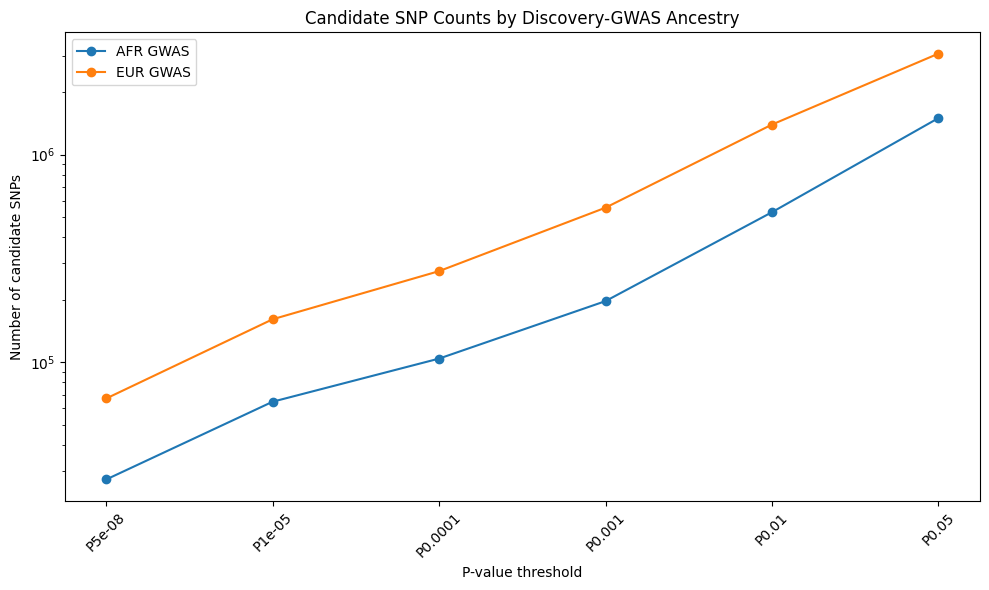

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    gwas_candidate_counts["Threshold"],
    gwas_candidate_counts["AFR_GWAS"],
    marker="o",
    label="AFR GWAS"
)

plt.plot(
    gwas_candidate_counts["Threshold"],
    gwas_candidate_counts["EUR_GWAS"],
    marker="o",
    label="EUR GWAS"
)

plt.yscale("log")

plt.xlabel("P-value threshold")
plt.ylabel("Number of candidate SNPs")
plt.title("Candidate SNP Counts by Discovery-GWAS Ancestry")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Compare candidate SNP identities

*Are they actually the same variants?*

For each threshold, **calculate**:

- AFR-only SNPs
- EUR-only SNPs
- shared SNPs
- total union

Two GWAS could have similar candidate counts but select very different variants.

In [ ]:
candidate_overlap_records = []

for threshold in THRESHOLDS:

    afr_snps = set(
        candidate_data["AFR-AFR"][threshold]["SNP"]
    )

    eur_snps = set(
        candidate_data["EUR-EUR"][threshold]["SNP"]
    )

    shared = afr_snps.intersection(eur_snps)
    afr_only = afr_snps - eur_snps
    eur_only = eur_snps - afr_snps
    union = afr_snps.union(eur_snps)

    candidate_overlap_records.append({
        "Threshold": threshold,
        "P_threshold": THRESHOLDS[threshold],
        "AFR_candidates": len(afr_snps),
        "EUR_candidates": len(eur_snps),
        "Shared": len(shared),
        "AFR_only": len(afr_only),
        "EUR_only": len(eur_only),
        "Union": len(union)
    })

candidate_overlap = pd.DataFrame(
    candidate_overlap_records
)

candidate_overlap

,Threshold,P_threshold,AFR_candidates,EUR_candidates,Shared,AFR_only,EUR_only,Union
0,P5e-08,5.000000e-08,27292,66996,25034,2258,41962,69254
1,P1e-05,1.000000e-05,64638,161236,58097,6541,103139,167777
2,P0.0001,1.000000e-04,104274,274975,92139,12135,182836,287110
3,P0.001,1.000000e-03,197201,555660,164988,32213,390672,587873
4,P0.01,1.000000e-02,528446,1396298,384536,143910,1011762,1540208
5,P0.05,5.000000e-02,1500187,3066477,923599,576588,2142878,3643065


## Calculate overlap percentages

What proportion of the AFR candidate set is also present in EUR?


What proportion of the EUR candidate set is also present in AFR?

In [ ]:
candidate_overlap["Shared_pct_of_AFR"] = (
    candidate_overlap["Shared"] /
    candidate_overlap["AFR_candidates"] *
    100
)

candidate_overlap["Shared_pct_of_EUR"] = (
    candidate_overlap["Shared"] /
    candidate_overlap["EUR_candidates"] *
    100
)

candidate_overlap

,Threshold,P_threshold,AFR_candidates,EUR_candidates,Shared,AFR_only,EUR_only,Union,Shared_pct_of_AFR,Shared_pct_of_EUR
0,P5e-08,5.000000e-08,27292,66996,25034,2258,41962,69254,91.726513,37.366410
1,P1e-05,1.000000e-05,64638,161236,58097,6541,103139,167777,89.880566,36.032276
2,P0.0001,1.000000e-04,104274,274975,92139,12135,182836,287110,88.362391,33.508137
3,P0.001,1.000000e-03,197201,555660,164988,32213,390672,587873,83.664890,29.692258
4,P0.01,1.000000e-02,528446,1396298,384536,143910,1011762,1540208,72.767322,27.539680
5,P0.05,5.000000e-02,1500187,3066477,923599,576588,2142878,3643065,61.565591,30.119222


# Jaccard similarity

he Jaccard index gives a single standardized measure of set similarity:

J(A,B)=
∣A∪B∣ /
∣A∩B∣
	​

1.0 = identical candidate sets

0.0 = no shared candidate SNPs

intermediate values = partial overlap

In [ ]:
candidate_overlap["Jaccard_similarity"] = (
    candidate_overlap["Shared"] /
    candidate_overlap["Union"]
)

candidate_overlap[
    [
        "Threshold",
        "Shared",
        "AFR_only",
        "EUR_only",
        "Jaccard_similarity"
    ]
]

,Threshold,Shared,AFR_only,EUR_only,Jaccard_similarity
0,P5e-08,25034,2258,41962,0.361481
1,P1e-05,58097,6541,103139,0.346275
2,P0.0001,92139,12135,182836,0.320919
3,P0.001,164988,32213,390672,0.280652
4,P0.01,384536,143910,1011762,0.249665
5,P0.05,923599,576588,2142878,0.253523


## Plot candidate-set overlap

Does the candidate-set similarity increase or decrease as the P-value threshold becomes more permissive.

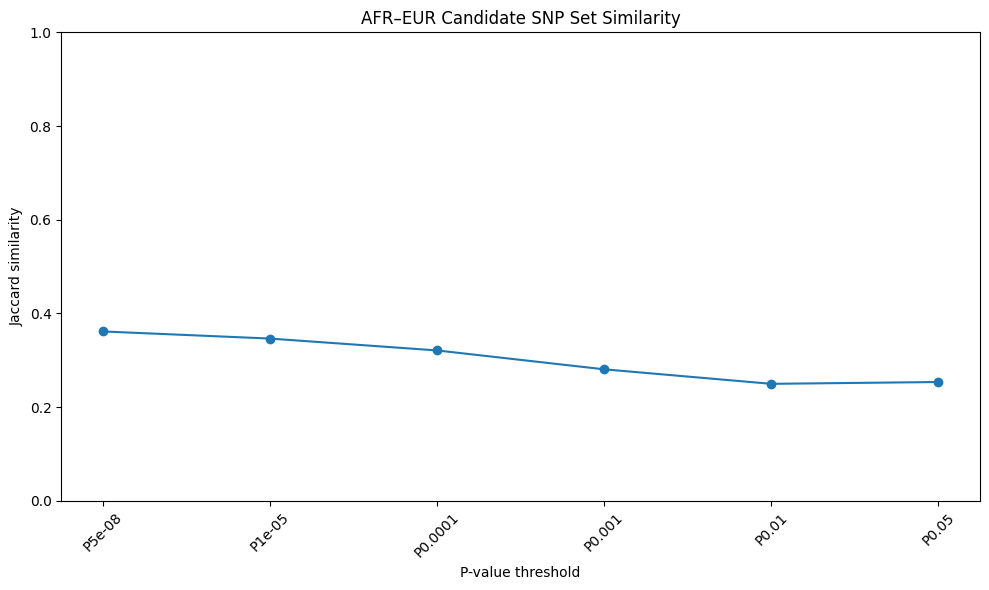

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    candidate_overlap["Threshold"],
    candidate_overlap["Jaccard_similarity"],
    marker="o"
)

plt.xlabel("P-value threshold")
plt.ylabel("Jaccard similarity")
plt.title("AFR–EUR Candidate SNP Set Similarity")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Examine chromosome distribution

Ancestry-related differences may not be uniformly distributed across the genome.

In [ ]:
#Confirming that chromosome information exists in the candidate files
for pipeline in candidate_data:

    example_threshold = "P5e-08"

    df = candidate_data[pipeline][example_threshold]

    print(
        pipeline,
        "columns:",
        df.columns.tolist()
    )

AFR-AFR columns: ['SNP', 'CHR', 'BP', 'A1', 'A2', 'EAF', 'BETA', 'SE', 'P', 'N']
AFR-EUR columns: ['SNP', 'CHR', 'BP', 'A1', 'A2', 'EAF', 'BETA', 'SE', 'P', 'N']
EUR-AFR columns: ['SNP', 'CHR', 'BP', 'A1', 'A2', 'EAF', 'BETA', 'SE', 'P', 'N']
EUR-EUR columns: ['SNP', 'CHR', 'BP', 'A1', 'A2', 'EAF', 'BETA', 'SE', 'P', 'N']


In [ ]:
# Creating chromosine summaries
'''
Are the differences in candidate SNP counts:

Broadly distributed across the genome, or
Concentrated on particular chromosomes?
'''

chromosome_records = []

for ancestry, pipeline in [
    ("AFR", "AFR-AFR"),
    ("EUR", "EUR-EUR")
]:

    for threshold in THRESHOLDS:

        df = candidate_data[pipeline][threshold]

        chromosome_counts = (
            df.groupby("CHR")
            .size()
            .reset_index(name="Candidate_SNPs")
        )

        chromosome_counts["GWAS_Ancestry"] = ancestry
        chromosome_counts["Threshold"] = threshold

        chromosome_records.append(
            chromosome_counts
        )

candidate_chromosome_counts = pd.concat(
    chromosome_records,
    ignore_index=True
)

candidate_chromosome_counts.head()

,CHR,Candidate_SNPs,GWAS_Ancestry,Threshold
0,1,1569,AFR,P5e-08
1,2,2249,AFR,P5e-08
2,3,2517,AFR,P5e-08
3,4,1076,AFR,P5e-08
4,5,826,AFR,P5e-08


##Compare candidate counts across chromosomes

**P5e-08**

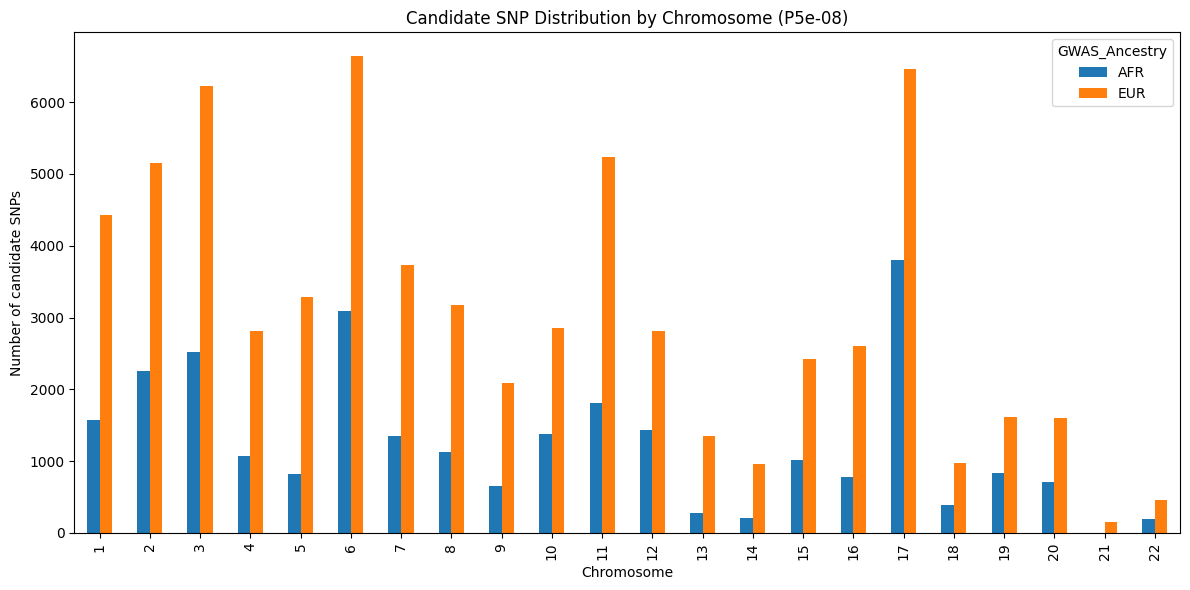

In [ ]:
selected_threshold = "P5e-08"

chromosome_plot_data = (
    candidate_chromosome_counts[
        candidate_chromosome_counts["Threshold"] == selected_threshold
    ]
    .pivot(
        index="CHR",
        columns="GWAS_Ancestry",
        values="Candidate_SNPs"
    )
)

chromosome_plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Chromosome")
plt.ylabel("Number of candidate SNPs")
plt.title(
    f"Candidate SNP Distribution by Chromosome ({selected_threshold})"
)
plt.tight_layout()
plt.show()

**P1e-05**

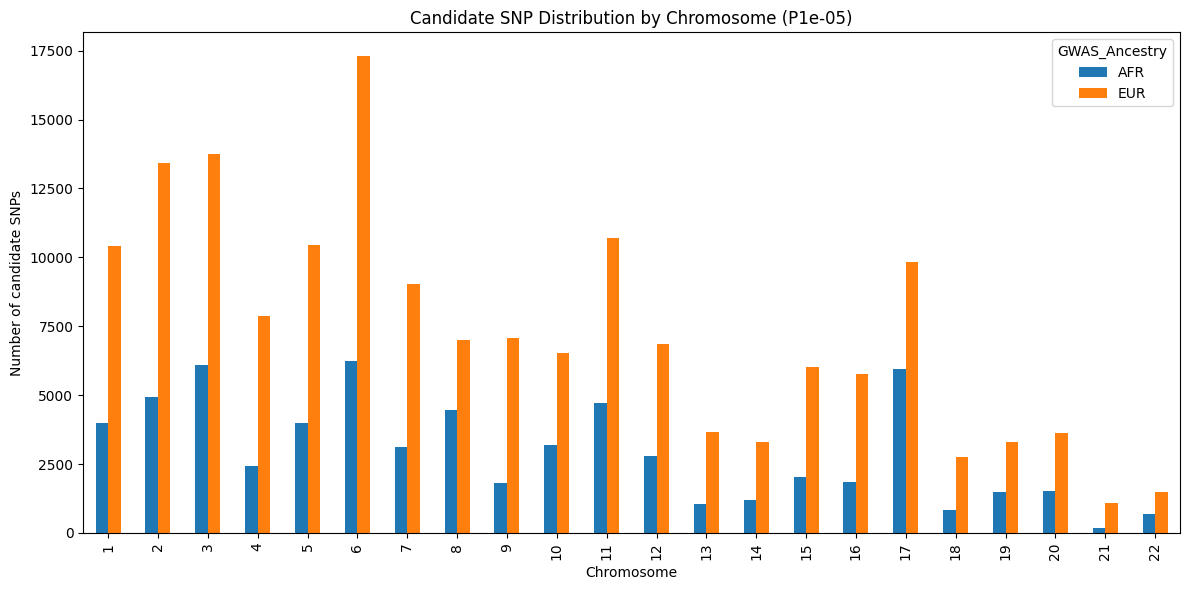

In [ ]:
selected_threshold = "P1e-05"

chromosome_plot_data = (
    candidate_chromosome_counts[
        candidate_chromosome_counts["Threshold"] == selected_threshold
    ]
    .pivot(
        index="CHR",
        columns="GWAS_Ancestry",
        values="Candidate_SNPs"
    )
)

chromosome_plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Chromosome")
plt.ylabel("Number of candidate SNPs")
plt.title(
    f"Candidate SNP Distribution by Chromosome ({selected_threshold})"
)
plt.tight_layout()
plt.show()

**P0.0001**

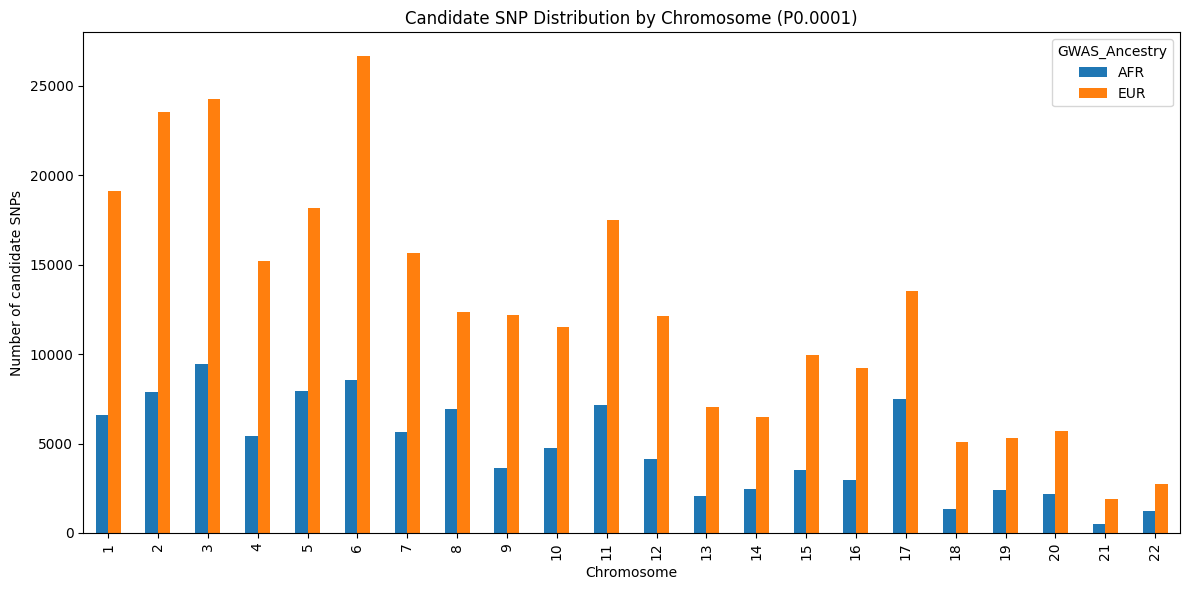

In [ ]:
selected_threshold = "P0.0001"

chromosome_plot_data = (
    candidate_chromosome_counts[
        candidate_chromosome_counts["Threshold"] == selected_threshold
    ]
    .pivot(
        index="CHR",
        columns="GWAS_Ancestry",
        values="Candidate_SNPs"
    )
)

chromosome_plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Chromosome")
plt.ylabel("Number of candidate SNPs")
plt.title(
    f"Candidate SNP Distribution by Chromosome ({selected_threshold})"
)
plt.tight_layout()
plt.show()

**P0.001**

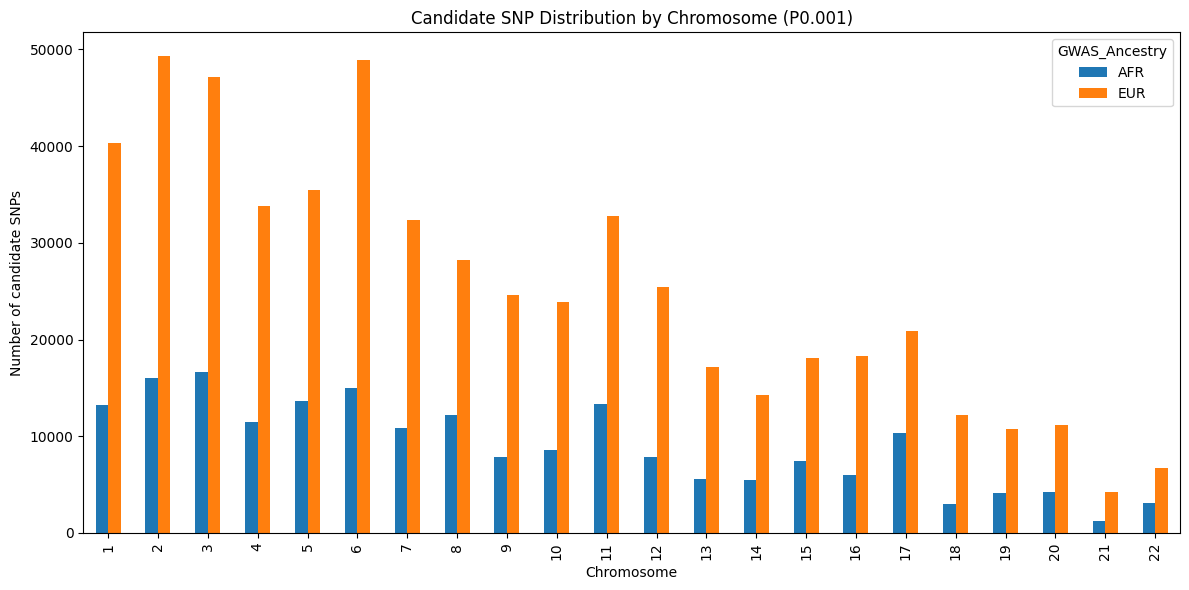

In [ ]:
selected_threshold = "P0.001"

chromosome_plot_data = (
    candidate_chromosome_counts[
        candidate_chromosome_counts["Threshold"] == selected_threshold
    ]
    .pivot(
        index="CHR",
        columns="GWAS_Ancestry",
        values="Candidate_SNPs"
    )
)

chromosome_plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Chromosome")
plt.ylabel("Number of candidate SNPs")
plt.title(
    f"Candidate SNP Distribution by Chromosome ({selected_threshold})"
)
plt.tight_layout()
plt.show()

**P0.01**

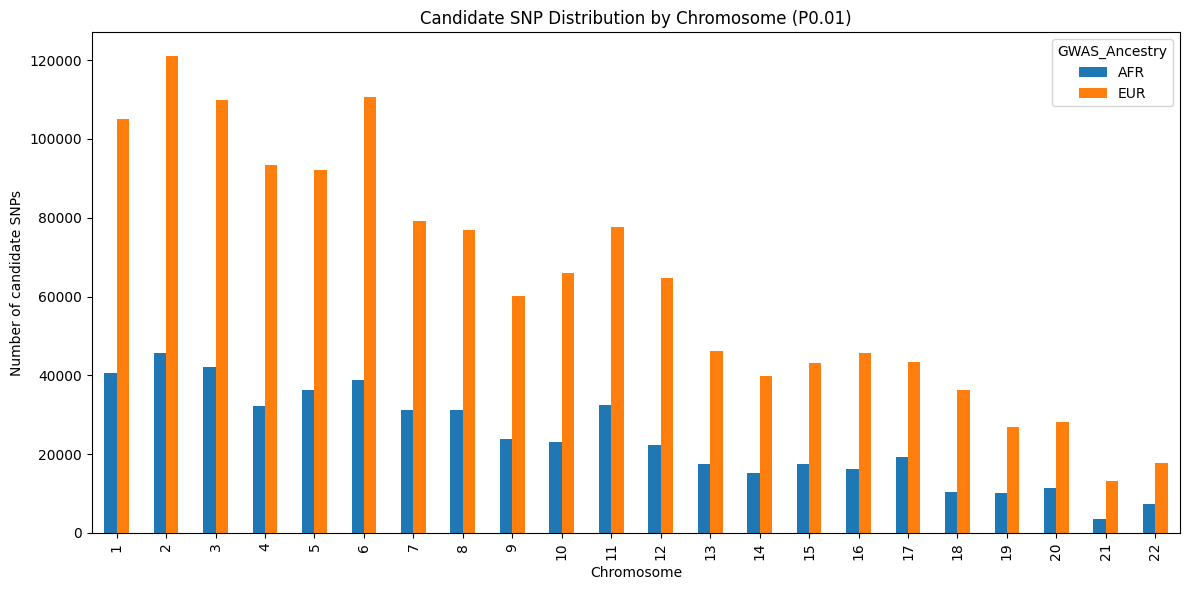

In [ ]:
selected_threshold = "P0.01"

chromosome_plot_data = (
    candidate_chromosome_counts[
        candidate_chromosome_counts["Threshold"] == selected_threshold
    ]
    .pivot(
        index="CHR",
        columns="GWAS_Ancestry",
        values="Candidate_SNPs"
    )
)

chromosome_plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Chromosome")
plt.ylabel("Number of candidate SNPs")
plt.title(
    f"Candidate SNP Distribution by Chromosome ({selected_threshold})"
)
plt.tight_layout()
plt.show()

**P0.05**

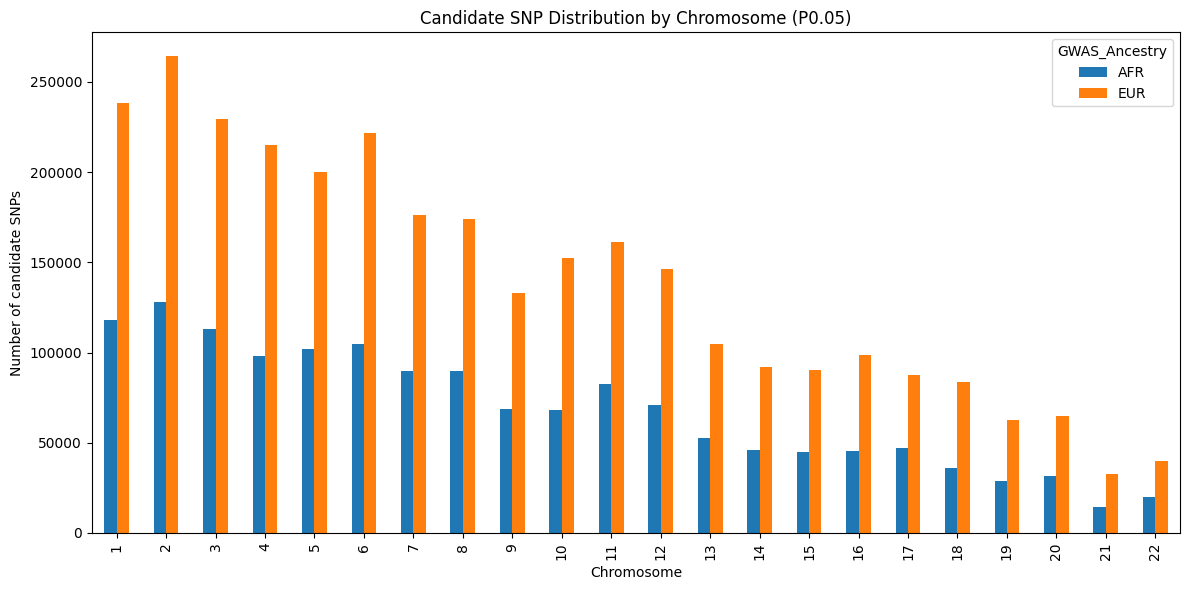

In [ ]:
selected_threshold = "P0.05"

chromosome_plot_data = (
    candidate_chromosome_counts[
        candidate_chromosome_counts["Threshold"] == selected_threshold
    ]
    .pivot(
        index="CHR",
        columns="GWAS_Ancestry",
        values="Candidate_SNPs"
    )
)

chromosome_plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Chromosome")
plt.ylabel("Number of candidate SNPs")
plt.title(
    f"Candidate SNP Distribution by Chromosome ({selected_threshold})"
)
plt.tight_layout()
plt.show()

## Check nested candidate sets

Because thresholds are progressively more permissive, candidate sets should generally be nested.

In [ ]:
def check_nested_candidate_sets(
    candidate_dict,
    pipeline
):
    previous_snps = set()

    results = []

    for threshold in THRESHOLDS:

        current_snps = set(
            candidate_dict[pipeline][threshold]["SNP"]
        )

        if previous_snps:
            nested = previous_snps.issubset(current_snps)
        else:
            nested = True

        results.append({
            "Pipeline": pipeline,
            "Threshold": threshold,
            "Nested_with_previous": nested,
            "Current_count": len(current_snps)
        })

        previous_snps = current_snps

    return pd.DataFrame(results)


afr_gwas_nested_check = check_nested_candidate_sets(
    candidate_data,
    "AFR-AFR"
)

eur_gwas_nested_check = check_nested_candidate_sets(
    candidate_data,
    "EUR-EUR"
)

print("AFR GWAS candidate-set nesting:")
display(afr_gwas_nested_check)

print("\nEUR GWAS candidate-set nesting:")
display(eur_gwas_nested_check)

AFR GWAS candidate-set nesting:


,Pipeline,Threshold,Nested_with_previous,Current_count
0,AFR-AFR,P5e-08,True,27292
1,AFR-AFR,P1e-05,True,64638
2,AFR-AFR,P0.0001,True,104274
3,AFR-AFR,P0.001,True,197201
4,AFR-AFR,P0.01,True,528446
5,AFR-AFR,P0.05,True,1500187



EUR GWAS candidate-set nesting:


,Pipeline,Threshold,Nested_with_previous,Current_count
0,EUR-EUR,P5e-08,True,66996
1,EUR-EUR,P1e-05,True,161236
2,EUR-EUR,P0.0001,True,274975
3,EUR-EUR,P0.001,True,555660
4,EUR-EUR,P0.01,True,1396298
5,EUR-EUR,P0.05,True,3066477


## Direct identity check between same-GWAS pipelines

Two files could contain the same number of SNPs but different SNPs.

So verify the actual sets.

In [ ]:
same_gwas_identity_records = []

for threshold in THRESHOLDS:

    afr_afr = set(
        candidate_data["AFR-AFR"][threshold]["SNP"]
    )

    afr_eur = set(
        candidate_data["AFR-EUR"][threshold]["SNP"]
    )

    eur_afr = set(
        candidate_data["EUR-AFR"][threshold]["SNP"]
    )

    eur_eur = set(
        candidate_data["EUR-EUR"][threshold]["SNP"]
    )

    same_gwas_identity_records.append({
        "Threshold": threshold,

        "AFR_GWAS_sets_identical":
            afr_afr == afr_eur,

        "EUR_GWAS_sets_identical":
            eur_afr == eur_eur,

        "AFR_AFR_count":
            len(afr_afr),

        "AFR_EUR_count":
            len(afr_eur),

        "EUR_AFR_count":
            len(eur_afr),

        "EUR_EUR_count":
            len(eur_eur)
    })

same_gwas_identity = pd.DataFrame(
    same_gwas_identity_records
)

same_gwas_identity

,Threshold,AFR_GWAS_sets_identical,EUR_GWAS_sets_identical,AFR_AFR_count,AFR_EUR_count,EUR_AFR_count,EUR_EUR_count
0,P5e-08,True,True,27292,27292,66996,66996
1,P1e-05,True,True,64638,64638,161236,161236
2,P0.0001,True,True,104274,104274,274975,274975
3,P0.001,True,True,197201,197201,555660,555660
4,P0.01,True,True,528446,528446,1396298,1396298
5,P0.05,True,True,1500187,1500187,3066477,3066477


## Create one master candidate comparison table

In [ ]:
candidate_summary = candidate_overlap.merge(
    gwas_candidate_counts,
    on=["Threshold", "P_threshold"],
    how="left"
)

candidate_summary

,Threshold,P_threshold,AFR_candidates,EUR_candidates,Shared,AFR_only,EUR_only,Union,Shared_pct_of_AFR,Shared_pct_of_EUR,Jaccard_similarity,AFR_GWAS,EUR_GWAS,Difference_EUR_minus_AFR,EUR_to_AFR_ratio
0,P5e-08,5.000000e-08,27292,66996,25034,2258,41962,69254,91.726513,37.366410,0.361481,27292,66996,39704,2.454785
1,P1e-05,1.000000e-05,64638,161236,58097,6541,103139,167777,89.880566,36.032276,0.346275,64638,161236,96598,2.494446
2,P0.0001,1.000000e-04,104274,274975,92139,12135,182836,287110,88.362391,33.508137,0.320919,104274,274975,170701,2.637043
3,P0.001,1.000000e-03,197201,555660,164988,32213,390672,587873,83.664890,29.692258,0.280652,197201,555660,358459,2.817734
4,P0.01,1.000000e-02,528446,1396298,384536,143910,1011762,1540208,72.767322,27.539680,0.249665,528446,1396298,867852,2.642272
5,P0.05,5.000000e-02,1500187,3066477,923599,576588,2142878,3643065,61.565591,30.119222,0.253523,1500187,3066477,1566290,2.044063


In [ ]:
candidate_summary = candidate_summary.merge(
    same_gwas_identity[
        [
            "Threshold",
            "AFR_GWAS_sets_identical",
            "EUR_GWAS_sets_identical"
        ]
    ],
    on="Threshold",
    how="left"
)

candidate_summary

,Threshold,P_threshold,AFR_candidates,EUR_candidates,Shared,AFR_only,EUR_only,Union,Shared_pct_of_AFR,Shared_pct_of_EUR,Jaccard_similarity,AFR_GWAS,EUR_GWAS,Difference_EUR_minus_AFR,EUR_to_AFR_ratio,AFR_GWAS_sets_identical_x,EUR_GWAS_sets_identical_x,AFR_GWAS_sets_identical_y,EUR_GWAS_sets_identical_y
0,P5e-08,5.000000e-08,27292,66996,25034,2258,41962,69254,91.726513,37.366410,0.361481,27292,66996,39704,2.454785,True,True,True,True
1,P1e-05,1.000000e-05,64638,161236,58097,6541,103139,167777,89.880566,36.032276,0.346275,64638,161236,96598,2.494446,True,True,True,True
2,P0.0001,1.000000e-04,104274,274975,92139,12135,182836,287110,88.362391,33.508137,0.320919,104274,274975,170701,2.637043,True,True,True,True
3,P0.001,1.000000e-03,197201,555660,164988,32213,390672,587873,83.664890,29.692258,0.280652,197201,555660,358459,2.817734,True,True,True,True
4,P0.01,1.000000e-02,528446,1396298,384536,143910,1011762,1540208,72.767322,27.539680,0.249665,528446,1396298,867852,2.642272,True,True,True,True
5,P0.05,5.000000e-02,1500187,3066477,923599,576588,2142878,3643065,61.565591,30.119222,0.253523,1500187,3066477,1566290,2.044063,True,True,True,True


# Saving comparison results

In [ ]:
COMPARISON_ROOT = Path(
    "/content/drive/MyDrive/PRS_T2D_comparison"
)

NOTEBOOK_05_RESULTS = (
    COMPARISON_ROOT /
    "PRS_candidate_SNP_comparison"
)

NOTEBOOK_05_RESULTS.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(NOTEBOOK_05_RESULTS)

Output directory:
/content/drive/MyDrive/PRS_T2D_comparison/PRS_candidate_SNP_comparison


*Saving the main tables*

In [ ]:
candidate_counts.to_csv(
    NOTEBOOK_05_RESULTS /
    "candidate_SNP_counts_all_pipelines.tsv",
    sep="\t",
    index=False
)

gwas_candidate_counts.to_csv(
    NOTEBOOK_05_RESULTS /
    "candidate_SNP_counts_by_GWAS_ancestry.tsv",
    sep="\t",
    index=False
)

candidate_overlap.to_csv(
    NOTEBOOK_05_RESULTS /
    "candidate_SNP_overlap.tsv",
    sep="\t",
    index=False
)

candidate_summary.to_csv(
    NOTEBOOK_05_RESULTS /
    "candidate_SNP_comparison_summary.tsv",
    sep="\t",
    index=False
)

same_gwas_identity.to_csv(
    NOTEBOOK_05_RESULTS /
    "same_GWAS_candidate_identity_QC.tsv",
    sep="\t",
    index=False
)

print("Comparison tables saved.")

Comparison tables saved.


## Save chromosome results

In [ ]:
if "CHR" in candidate_data["AFR-AFR"]["P5e-08"].columns:

    candidate_chromosome_counts.to_csv(
        NOTEBOOK_05_RESULTS /
        "candidate_SNP_chromosome_distribution.tsv",
        sep="\t",
        index=False
    )

    print("Chromosome distribution table saved.")
else:
    print(
        "CHR column unavailable; chromosome table was not saved."
    )

Chromosome distribution table saved.


# Final QC summary

In [ ]:
print("NOTEBOOK 05 FINAL QC")
print()

# Check same-GWAS candidate identity

afr_identity_pass = (
    same_gwas_identity["AFR_GWAS_sets_identical"]
    .all()
)

eur_identity_pass = (
    same_gwas_identity["EUR_GWAS_sets_identical"]
    .all()
)

print(
    "AFR GWAS candidate sets identical across LD references:",
    "PASS" if afr_identity_pass else "FAIL"
)

print(
    "EUR GWAS candidate sets identical across LD references:",
    "PASS" if eur_identity_pass else "FAIL"
)

# Check nested candidate sets

afr_nested_pass = (
    afr_gwas_nested_check["Nested_with_previous"]
    .all()
)

eur_nested_pass = (
    eur_gwas_nested_check["Nested_with_previous"]
    .all()
)

print(
    "AFR candidate sets nested across thresholds:",
    "PASS" if afr_nested_pass else "FAIL"
)

print(
    "EUR candidate sets nested across thresholds:",
    "PASS" if eur_nested_pass else "FAIL"
)

print()

if all([
    afr_identity_pass,
    eur_identity_pass,
    afr_nested_pass,
    eur_nested_pass
]):
    print(
        "OVERALL QC: PASS — candidate SNP comparison is internally consistent."
    )
else:
    print(
        "OVERALL QC: REVIEW REQUIRED — investigate failed checks before proceeding."
    )

NOTEBOOK 05 FINAL QC

AFR GWAS candidate sets identical across LD references: PASS
EUR GWAS candidate sets identical across LD references: PASS
AFR candidate sets nested across thresholds: PASS
EUR candidate sets nested across thresholds: PASS

OVERALL QC: PASS — candidate SNP comparison is internally consistent.


###### Discovery-GWAS ancestry substantially changes the candidate SNP landscape, while changing the LD-reference ancestry does not alter the candidate SNP set before LD clumping.